### Импорты и загрузка датасета

In [1]:
import pandas as pd
import kagglehub
from typing import List
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_score,recall_score, roc_auc_score, ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
data_path = kagglehub.dataset_download(
    "jessemostipak/hotel-booking-demand",
    output_dir="data"
)

### Описание датасета и выбор метрик (копия из ДЗ 1)

**Выбранный датасет**: [Hotel Booking Demand](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand)

Датасет содержит информацию о бронированиях городского и курортного отелей: когда была сделана бронь, на сколько ночей, кто является гостями, какой тип питания забронирован и другое.

**Бизнес-постановка задачи**

Реализовать модель-классификатор для определения, будет ли отменено бронирование. Это может позволить гостиницам заранее оценивать риск отмены, тем самым эффективнее планировать загрузку номеров и принимать решения по управлению бронированиями (например, если один человек делает бронирования и всегда отменяет их, стоит ли его занести в черный список).

**ML-задача**

Бинарная классификация. Для каждого бронирования необходимо предсказать, будет ли оно отменено (is_canceled = 1) или сохранится (is_canceled = 0).

**Выбор и обоснование метрик**

Основная метрика - **F1-score** для положительного класса (is_canceled = 1).
Эта метрика учитывает одновременно precision и recall: необходимо выявлять как можно больше бронирований, которые будут отменены, не создавая при этом слишком много ложных предупреждений.

Дополнительно:

- Precision - доля действительно отменённых бронирований среди всех бронирований, которые модель предсказала как отменённые. Высокий precision означает, что модель редко ошибочно помечает сохранённые бронирования как отменённые.

- Recall - доля найденных моделью отмен среди всех бронирований, которые действительно были отменены. Высокий recall означает, что модель пропускает мало реальных отмен.

- ROC-AUC - оценивает способность модели различать отменённые и сохранённые бронирования при различных порогах классификации.

**Описание столбцов датасета**

| Столбец | Перевод и краткое описание |
|---|---|
| `is_canceled` | Отмена бронирования: 1 - отменено, 0 - не отменено. |
| `lead_time` | Количество дней между оформлением бронирования и датой прибытия. |
| `arrival_date_year` | Год прибытия гостя. |
| `arrival_date_month` | Месяц прибытия гостя. |
| `arrival_date_week_number` | Номер недели года, на которую приходится прибытие. |
| `arrival_date_day_of_month` | День месяца, на который запланировано прибытие. |
| `stays_in_weekend_nights` | Количество ночей проживания в выходные (суббота и воскресенье). |
| `stays_in_week_nights` | Количество ночей проживания в будние дни (понедельник — пятница). |
| `adults` | Количество взрослых гостей. |
| `children` | Количество детей. |
| `babies` | Количество младенцев. |
| `meal` | Тип питания, включённого в бронирование. |
| `country` | Страна происхождения гостя (код страны ISO 3155–3:2013). |
| `market_segment` | Сегмент рынка, к которому относится бронирование (Например, “TA” - “Travel Agents”, “TO” - “Tour Operators”). |
| `distribution_channel` | Канал, через который оформлено бронирование. |
| `is_repeated_guest` | Был ли уже этот гость: 1 — да, 0 — нет. |
| `previous_cancellations` | Количество предыдущих бронирований, отменённых гостем. |
| `previous_bookings_not_canceled` | Количество предыдущих бронирований, которые не были отменены. |
| `reserved_room_type` | Код забронированного типа номера. |
| `assigned_room_type` | Код фактически назначенного типа номера. |
| `booking_changes` | Количество изменений бронирования после оформления. |
| `deposit_type` | Тип депозита или условия предоплаты. |
| `agent` | Идентификатор турагентства, оформившего бронирование. |
| `company` | Идентификатор компании, оформившей или оплачивающей бронирование. |
| `days_in_waiting_list` | Количество дней ожидания подтверждения бронирования. |
| `customer_type` | Тип бронирования: индивидуальное, групповое, контрактное или связанное с другими индивидуальными бронированиями. |
| `adr` | Средняя стоимость проживания за ночь. |
| `required_car_parking_spaces` | Количество необходимых парковочных мест. |
| `total_of_special_requests` | Количество особых пожеланий гостя. |
| `reservation_status` | Последний статус бронирования: отменено, выезд состоялся или гость не прибыл. |
| `reservation_status_date` | Дата последнего изменения статуса бронирования. |

### Предобработка

In [4]:
df = pd.read_csv(data_path + "/hotel_bookings.csv")

План предобработки из ДЗ 1:
- удалить утечки: `reservation_status`, `reservation_status_date`
- исправить тип столбцов `children`, `agent` и `company` с float64 на int
- убрать аномалии: `adr` < 0 и `adr` = 5400, брони без гостей, `adults` > 4, брони без ночей
- решить, что делать с дубликатами, так как их очень много
- заполнить пропуски: `children` удалить строки с пропусками, `country` -> Unknown, `agent` -> «нет агента»; `company` заменить флагом has_company
- заменить количество заказанных парковочных мест на признак need_parking
- для `country` нужны top-N + «Other» или target/frequency encoding
- месяц перевести в число
- добавить признаки `total_nights`, `total_guests`

#### Удаление утечек: `reservation_status`, `reservation_status_date`

In [5]:
df.drop(columns=['reservation_status', 'reservation_status_date'], inplace=True)

Хоть в прошлом дз я и решила оставлять признак assigned_room_type, так как он не супер сильно коррелирует с целевой переменной, однако если сравнить, совпал ли выданный номер с забронированным, при смене номера отменяется 5% броней, без смены 42% -> если признак останется, модель, скорее всего, будет сильно на него опираться, и метрики окажутся завышенными, поэтому его тоже уберем

In [6]:
df.groupby(df['reserved_room_type'] != df['assigned_room_type'])['is_canceled'].mean()

False    0.415629
True     0.053764
Name: is_canceled, dtype: float64

In [7]:
df.drop(columns=['assigned_room_type'], inplace=True)

#### Исправление типа столбцов `children`, `agent` и `company` с float64 на int

In [8]:
df = df.astype({'children': int, 'agent': int, 'company': int}, errors='ignore')

#### Заполнение пропусков
- `children` удалить строки с пропусками
- `country` -> Unknown
- `agent` -> «нет агента»  + флаш `has_agent`
- `company` заменить флагом `has_company`

In [9]:
# Удаляем строки с пустыми children 
df = df.dropna(subset=['children'])
df['children'] = df['children'].astype(int)

# Пустые `country` -> Unknown
df['country'] = df['country'].fillna('Unknown')

# Пустые `agent` -> 0, такого ID в данных нет (минимальный ID — 1), приводим к int еще раз, добавляем флаг 'has_agent'
df['has_agent'] = df['agent'].notna().astype(int)
df['agent'] = df['agent'].fillna(0).astype(int)

# Пустые `company` -> отдельный флаг `has_company` (1 — компания есть, 0 — нет)
df['has_company'] = df['company'].notna().astype(int)
df = df.drop(columns=['company'])

In [10]:
print(f"Пропущенных значений: {df.isna().sum().sum()}")

Пропущенных значений: 0


#### Обработка дубликатов

В ДЗ 1 была таблица с вариантами обработки дубликатов.

Две наиболее разумные стратегии их обработки:

| Стратегия | Плюсы | Минусы |
|---|---|---|
| **Удалить дубли** (`drop_duplicates`) | Убирает утечку между train и test; каждый уникальный набор признаков считается один раз; статистики становятся честнее. | Теряется информация о размере блока, хотя она очень значима; реальная доля отмен по номерам занижается. |
| **Агрегировать** (удалить дубли и добавить признак `group_size`) | Сохраняет информацию о размере блока как признак; нет утечки между train и test. | Нужно точно знать, что бронь является частью блока (у отеля обычно есть такие данные). |

In [11]:
feature_columns = df.columns.drop('is_canceled').tolist()
df['group_size'] = (
    df.groupby(feature_columns, dropna=False)['is_canceled'].transform('size')
)

n_rows_before = len(df)
print(f'Доля отмен до удаления дублей: {df["is_canceled"].mean():.3f}')
df = df.drop_duplicates().reset_index(drop=True)
print(f'Строк до: {n_rows_before}, после: {len(df)}')
print(f'Доля отмен после удаления дублей: {df["is_canceled"].mean():.3f}')

Доля отмен до удаления дублей: 0.370
Строк до: 119386, после: 86137
Доля отмен после удаления дублей: 0.275


#### Обработка временных признаков (месяц, день и т.д)

In [12]:
MONTHS = ['January', 'February', 'March', 'April', 'May', 'June', 'July',
          'August', 'September', 'October', 'November', 'December']
MONTH_TO_NUMBER = {month: number for number, month in enumerate(MONTHS, start=1)}

df['arrival_date_month'] = df['arrival_date_month'].map(MONTH_TO_NUMBER)

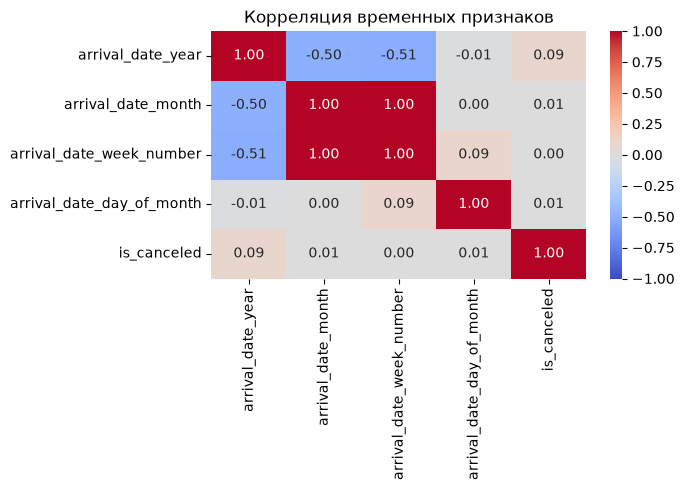

In [13]:
TIME_COLUMNS = ['arrival_date_year', 'arrival_date_month',
                'arrival_date_week_number', 'arrival_date_day_of_month']

# Корреляция временных признаков между собой и с целевой переменной
plt.figure(figsize=(7, 5))
sns.heatmap(df[TIME_COLUMNS + ['is_canceled']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Корреляция временных признаков')
plt.tight_layout()
plt.show()

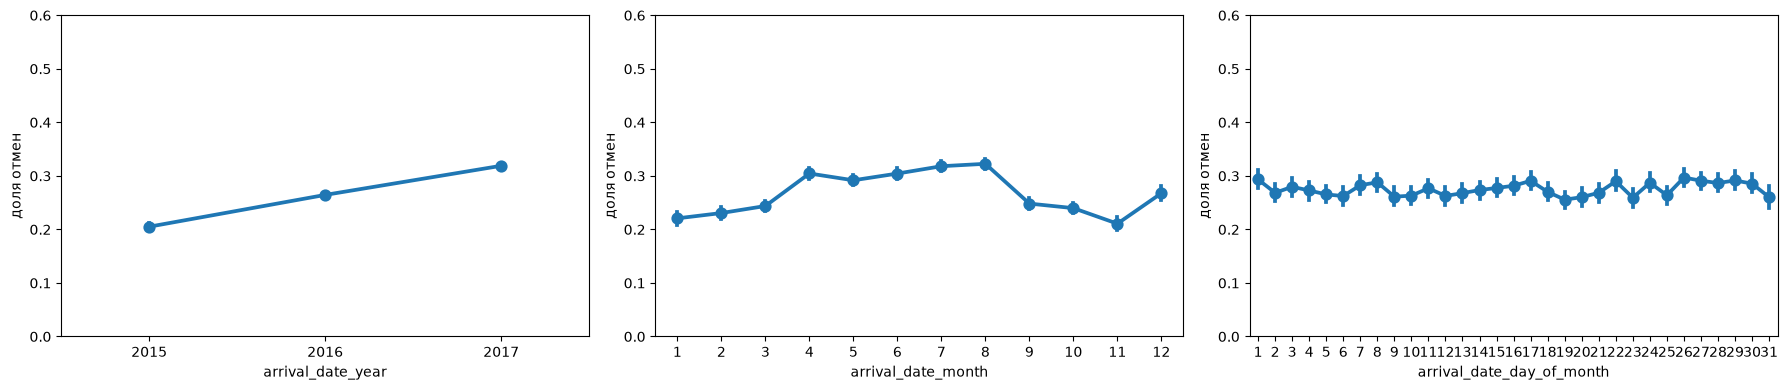

In [14]:
# Также смотрим долю отмен по значениям признаков
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, column in zip(axes, ['arrival_date_year', 'arrival_date_month',
                             'arrival_date_day_of_month']):
    sns.pointplot(data=df, x=column, y='is_canceled', ax=ax)
    ax.set_ylabel('доля отмен')
    ax.set_ylim(0, 0.6)
plt.tight_layout()
plt.show()

`arrival_date_week_number` почти полностью дублирует месяц (что логично), и сам по себе с таргетом не связан -> удаляем его;

`arrival_date_day_of_month` с таргетом тоже не связан, на сезонность больше влияет месяц нежели день конкретного месяца  -> удаляем его;

`arrival_date_year` - доля отмен по годам растети, но признак нельзя обобщить на будущие периоды: для модели 2018 год будет значением, которого не было в обучении;

In [15]:
df = df.drop(columns=['arrival_date_year', 'arrival_date_day_of_month', 'arrival_date_week_number'])

#### Чистка аномалий: `adr` < 0 и `adr` = 5400, брони без гостей, `adults` > 4, брони без ночей

In [16]:
# adr < 0 - средняя цена за ночь не может быть отрицательной, удаляем
df = df[df['adr'] >= 0]

In [17]:
# Бронирования с аномальной средней ценой за ночь (adr)

# Квантили средней цены за ночь (adr)
print(f"Квантили средней цены за ночь:\n{df['adr'].quantile([0.9, 0.95, 0.99])}")

Квантили средней цены за ночь:
0.90    174.67
0.95    205.00
0.99    262.00
Name: adr, dtype: float64


In [18]:
abnormal_adr_bookings = df[df['adr'] > 1000]
abnormal_adr_bookings[['is_canceled', 'adr']]

,is_canceled,adr
38081,1,5400.0


Такой дорогой отель - единственный и его отменили, возможно, это была неправильная бронь -> удалим его

In [19]:
df = df[~df.index.isin(abnormal_adr_bookings.index)]

In [20]:
# Брони без гостей (adults + children + babies = 0) - удаляем

total_guests = df['adults'] + df['children'] + df['babies']
df = df[total_guests > 0]

In [21]:
# Брони с более чем 4 взрослыми удаляем

df = df[df['adults'] <= 4]

In [22]:
# Брони без ночей (stays_in_weekend_nights + stays_in_week_nights = 0) - удаляем

total_nights = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df = df[total_nights > 0]

#### Замена количества заказанных парковочных мест на признак `need_parking`

In [23]:
df['need_parking'] = (df['required_car_parking_spaces'] > 0).astype(int)
df = df.drop(columns=['required_car_parking_spaces'])

#### Предобработка признака `country`: top-N + «Other» или target/frequency encoding

Список топ-N стран нужно считать только на train, иначе будет утечка

#### Новые признаки `total_nights`, `total_guests`

In [24]:
df['total_nights'] = total_nights
df['total_guests'] = total_guests

#### Undefined строки

In [25]:
for column in df.columns:
    if df[column].dtype == 'str':
        if df[column].str.contains('Undefined', na=False).any():
            print(f"Столбец: {column}")
            display(df[df[column].str.contains('Undefined', na=False)])

Столбец: meal


,hotel,is_canceled,lead_time,arrival_date_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,...,days_in_waiting_list,customer_type,adr,total_of_special_requests,has_agent,has_company,group_size,need_parking,total_nights,total_guests
2759,Resort Hotel,0,105,11,2,4,2,0,0,Undefined,...,65,Transient-Party,69.00,0,1,0,24,0,6,2
2761,Resort Hotel,0,62,11,2,4,2,0,0,Undefined,...,0,Transient-Party,69.00,0,1,0,4,0,6,2
2762,Resort Hotel,0,62,11,2,4,1,0,0,Undefined,...,0,Transient-Party,49.00,0,1,0,1,0,6,1
2763,Resort Hotel,0,105,11,2,4,2,0,0,Undefined,...,65,Transient-Party,71.00,0,1,0,1,0,6,2
2764,Resort Hotel,0,105,11,2,4,1,0,0,Undefined,...,65,Transient-Party,18.50,0,1,0,1,0,6,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33378,Resort Hotel,0,81,8,2,2,2,2,0,Undefined,...,0,Transient,351.00,2,0,0,1,1,4,4
33382,Resort Hotel,0,191,8,2,5,2,1,0,Undefined,...,0,Transient,169.98,2,1,0,1,1,7,3
33383,Resort Hotel,0,29,8,0,1,2,1,0,Undefined,...,0,Group,204.00,2,1,0,1,1,1,3
33412,Resort Hotel,0,8,8,0,2,2,0,0,Undefined,...,0,Transient,266.06,0,1,0,1,1,2,2


Столбец: distribution_channel


,hotel,is_canceled,lead_time,arrival_date_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,...,days_in_waiting_list,customer_type,adr,total_of_special_requests,has_agent,has_company,group_size,need_parking,total_nights,total_guests
11220,Resort Hotel,0,103,7,2,3,2,1,0,HB,...,0,Transient,112.7,2,0,0,1,1,5,3


In [26]:
# Скорее всего Undefined и SC в meal означают одно и то же - «без питания»
df['meal'] = df['meal'].replace('Undefined', 'SC')

# Удаляем строки с distribution_channel = Undefined
df = df[df['distribution_channel'] != 'Undefined'].reset_index(drop=True)

#### Финальный датасет

In [27]:
print(df.shape)
df.info()

(85364, 30)
<class 'pandas.DataFrame'>
RangeIndex: 85364 entries, 0 to 85363
Data columns (total 30 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           85364 non-null  str    
 1   is_canceled                     85364 non-null  int64  
 2   lead_time                       85364 non-null  int64  
 3   arrival_date_month              85364 non-null  int64  
 4   stays_in_weekend_nights         85364 non-null  int64  
 5   stays_in_week_nights            85364 non-null  int64  
 6   adults                          85364 non-null  int64  
 7   children                        85364 non-null  int64  
 8   babies                          85364 non-null  int64  
 9   meal                            85364 non-null  str    
 10  country                         85364 non-null  str    
 11  market_segment                  85364 non-null  str    
 12  distribution_channel           

### Разбиение на Train Test

#### Отбор признаков

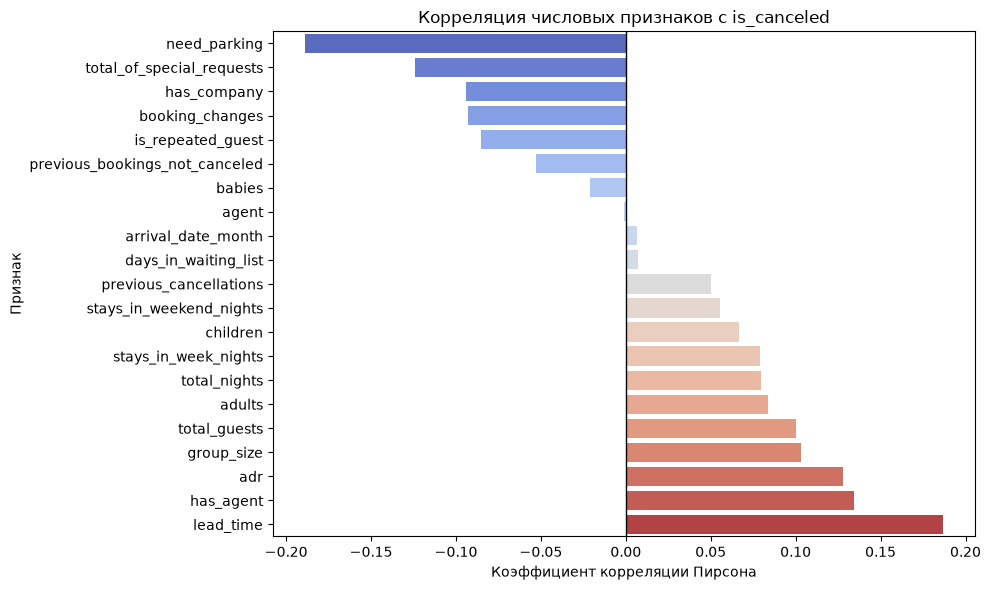

In [28]:
# Корреляция числовых признаков с целевой переменной
numeric_df = df.select_dtypes(include='number')

target_corr = (
    numeric_df.corr()['is_canceled']
    .drop('is_canceled')
    .sort_values()
)

plt.figure(figsize=(10, 6))
sns.barplot(x=target_corr.values, y=target_corr.index, palette='coolwarm')

plt.title('Корреляция числовых признаков с is_canceled')
plt.xlabel('Коэффициент корреляции Пирсона')
plt.ylabel('Признак')
plt.axvline(0, color='black', linewidth=1)
plt.tight_layout()
plt.show()

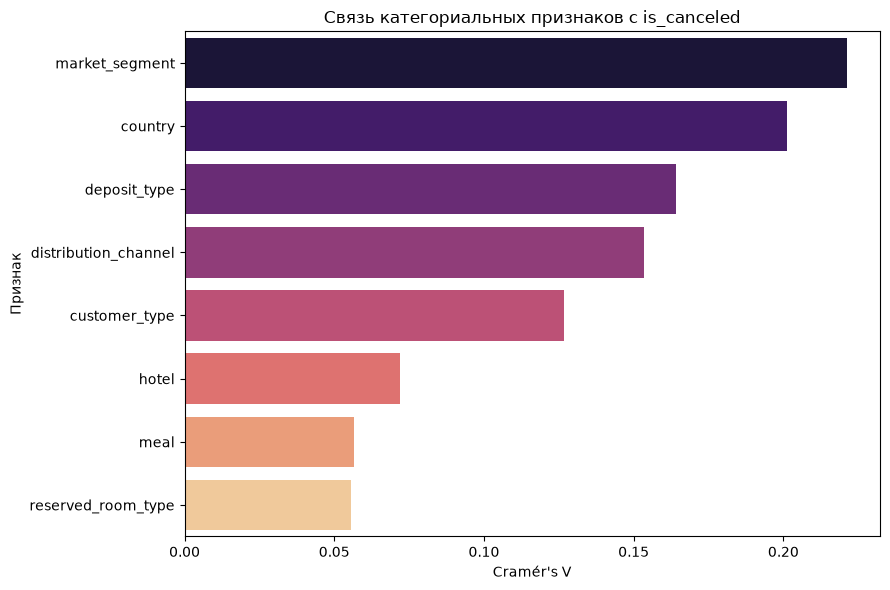

In [29]:
# Корреляция категориальных признаков с целевой переменной
# Для оценки силы связи между категориальными переменными можно использовать коэффициент Крамера
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table)[0]
    n = table.to_numpy().sum()
    r, k = table.shape

    if n == 0 or min(r, k) <= 1:
        return np.nan

    return np.sqrt(chi2 / (n * min(r - 1, k - 1)))

cramers_corr = pd.Series({
    col: cramers_v(df[col], df['is_canceled'])
    for col in cat_cols
}).sort_values(ascending=False)

plt.figure(figsize=(9, 6))
sns.barplot(x=cramers_corr.values, y=cramers_corr.index, palette='magma')

plt.title("Связь категориальных признаков с is_canceled")
plt.xlabel("Cramér's V")
plt.ylabel("Признак")
plt.tight_layout()
plt.show()

Итоговый набор признаков:

- поведенческие признаки клиента: need_parking, total_of_special_requests, booking_changes, is_repeated_guest, previous_cancellations, previous_bookings_not_canceled

- параметры брони: lead_time (самая сильная корреляция с таргетом), adr, total_nights, total_guests, days_in_waiting_list, reserved_room_type, meal, hotel, arrival_date_month (сезонность)

- канал продажи: market_segment, distribution_channel, customer_type, deposit_type, has_agent, has_company

- country: top-N стран + другие 

- 'group_size' (возможно, но пока попробуем без)

#### Разбиение

In [30]:
RANDOM_STATE = 42
TARGET = 'is_canceled'

X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)


features = [
    'need_parking',
    'total_of_special_requests',
    'booking_changes',
    'is_repeated_guest',
    'previous_cancellations',
    'previous_bookings_not_canceled',

    'lead_time',
    'adr',
    'total_nights',
    'total_guests',
    'days_in_waiting_list',
    'reserved_room_type',
    'meal',
    'hotel',
    'arrival_date_month',

    'market_segment',
    'distribution_channel',
    'customer_type',
    'deposit_type',
    'has_agent',
    'has_company',

    'country'
]

X_train = X_train[features]
X_test = X_test[features]

print(f'Train: {X_train.shape}, доля отмен {y_train.mean():.3f}')
print(f'Test: {X_test.shape}, доля отмен {y_test.mean():.3f}')

Train: (68291, 22), доля отмен 0.277
Test: (17073, 22), доля отмен 0.277


Делим данные случайно в пропорции 80/20 со стратификацией по is_canceled. Классы несбалансированы (27.7% отмен), и без стратификации доля отмен в test может отличаться от train.

### Функция оценки

In [31]:
def evaluate(model, X: pd.DataFrame, y: pd.Series) -> dict:
    """Считает выбранные метрики качества для положительного класса (отмена)."""
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]
    return {
        'F1': f1_score(y, y_pred, zero_division=0),
        'Precision': precision_score(y, y_pred, zero_division=0),
        'Recall': recall_score(y, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y, y_proba),
    }

results = {}

### Измерение качества константного предсказания

In [32]:
results = {}

for strategy in ['most_frequent', 'stratified']:
    # Создаем константную модель
    dummy = DummyClassifier(strategy=strategy, random_state=RANDOM_STATE)

    # Обучаем на тренировочных данных
    dummy.fit(X_train, y_train)

    # Проверяем качество на тестовых данных
    results[f'Dummy ({strategy})'] = evaluate(dummy, X_test, y_test)

pd.DataFrame(results).T

,F1,Precision,Recall,ROC-AUC
Dummy (most_frequent),0.000000,0.00000,0.000000,0.500000
Dummy (stratified),0.274034,0.27624,0.271863,0.499292


`most_frequent` всегда предсказывает «не отменено». Accuracy у такой модели была бы примерно 72%, но F1, precision и recall для отмен равны 0, а ROC-AUC 0.5. Это еще раз показывает, почему accuracy не подходит для задачи.

`stratified` предсказывает случайно с долей отмен как в train. F1 = 0.27, это уровень случайного угадывания.


### Финальная предобработка признаков

#### Страны: Top-20 + Other

In [33]:
# Находим 20 самых частых стран только на train
top_countries = X_train['country'].value_counts().head(20).index

X_train = X_train.copy()
X_test = X_test.copy()

# Все остальные страны заменяем на Other
X_train['country'] = X_train['country'].where(X_train['country'].isin(top_countries), 'Other')

X_test['country'] = X_test['country'].where(X_test['country'].isin(top_countries), 'Other')

print('Количество стран после обработки:')
print(X_train['country'].nunique())

Количество стран после обработки:
21


#### Обработка признаков

In [34]:
# Бинарные признаки - оставляем 0 и 1
binary_columns = [
    'has_agent',
    'has_company',
    'need_parking',
    'is_repeated_guest'
]

# Категориальные признаки
cat_columns = X_train.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

# Добавляем месяц к категориальным
if 'arrival_date_month' not in cat_columns:
    cat_columns.append('arrival_date_month')

# Числовые признаки
num_columns = X_train.select_dtypes(
    include=['number']
).columns.tolist()

# Убираем бинарные признаки и месяц из числовых
num_columns = [
    col for col in num_columns
    if col not in binary_columns and col != 'arrival_date_month'
]

print('Бинарные:', binary_columns)
print('Категориальные:', cat_columns)
print('Числовые:', num_columns)

Бинарные: ['has_agent', 'has_company', 'need_parking', 'is_repeated_guest']
Категориальные: ['reserved_room_type', 'meal', 'hotel', 'market_segment', 'distribution_channel', 'customer_type', 'deposit_type', 'country', 'arrival_date_month']
Числовые: ['total_of_special_requests', 'booking_changes', 'previous_cancellations', 'previous_bookings_not_canceled', 'lead_time', 'adr', 'total_nights', 'total_guests', 'days_in_waiting_list']


In [35]:
preprocessor = ColumnTransformer(
    transformers=[
        # Категориальные признаки
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_columns),

        # Числовые признаки
        ('num', StandardScaler(), num_columns),

        # Бинарные признаки оставляем без изменений
        ('binary', 'passthrough', binary_columns)
    ]
)

### Обучение модели (Логистическая регрессия) и предсказания

In [36]:
logreg = Pipeline([
    ('preprocessing', preprocessor),
    ('model', LogisticRegression(
        max_iter=1000,
        # учитываем дисбаланс классов
        class_weight='balanced',
        random_state=RANDOM_STATE
    ))
])

# Обучение
logreg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['need_parking','total_of_special_requests','booking_changes',..., 'has_agent','has_company','country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specif

In [37]:
results['Logistic Regression (train)'] = evaluate(logreg, X_train, y_train)

In [38]:
logreg_results = evaluate(logreg, X_test, y_test)

print('Результаты логистической регрессии:')
print(logreg_results)

Результаты логистической регрессии:
{'F1': 0.6303641648144982, 'Precision': 0.5294371051120046, 'Recall': 0.7788339670468948, 'ROC-AUC': 0.8344892609715543}


In [39]:
results['Logistic Regression (test)'] = logreg_results

results_df = pd.DataFrame(results).T

display(results_df)

,F1,Precision,Recall,ROC-AUC
Dummy (most_frequent),0.000000,0.000000,0.000000,0.500000
Dummy (stratified),0.274034,0.276240,0.271863,0.499292
Logistic Regression (train),0.623024,0.523199,0.769921,0.832547
Logistic Regression (test),0.630364,0.529437,0.778834,0.834489


### Вывод

Логистическая регрессия значительно превосходит константные предсказания: F1 вырос с 0.28 до 0.63, ROC-AUC с 0.50 до 0.83. Значит, выбранные признаки действительно содержат информацию о риске отмены, и модель не угадывает случайно. Также, судя по метрикам, модель не переобучилась.

Recall = 0.78: модель находит 78% реальных отмен. Это отвечает бизнес-цели: заранее выявить брони, которые могут отменится.

Precision = 0.53: только половина броней, помеченных как «будет отменена», действительно отменяется. Такой перекос в сторону recall - следствие class_weight='balanced': мы штрафуем модель за пропуск редкого класса сильнее, и она чаще предсказывает отмену.

Пропущенная отмена означает пустой номер и потерянную выручку. Ложная тревога обходится дешевле: например, отель запросит подтверждение брони или предоплату у клиента, который и так приедет. Если же ложные срабатывания станут дорогими (например, при агрессивном overbooking), баланс между precision и recall можно сдвинуть порогом вероятности без переобучения модели, ведь ROC-AUC от порога не зависит.

Чтобы улучшить метрики, можно детальнее поработать над признаками, например, `agent` заменён флагом has_agent, хотя по EDA у отдельных агентов доля отмен выше - кодирование топ-N агентов может добавить качества.
Линейная модель не улавливает взаимодействия признаков (например, «Non Refund × групповая бронь»). Также можно попробовать нелинейные модели (деревья, бустинг) и подбор порога классификации под бизнес-метрику, исходя из стоимости ложных и пропущенных отмен.